# 12 · Code It Yourself: from a column of 1s to logistic regression

You build your own mini machine-learning library, one function at a time, the way the professor builds it in class.
Every task ends with a **check** that tells you instantly whether your code is right, and *why* if it isn't.

**How to play**
1. Read the short "idea" text, then write the code where it says `# YOUR CODE HERE`. Delete the `raise NotImplementedError` line.
2. Run the cell. ✅ means cleared; ❌ tells you what is wrong (shape or values, with expected vs got).
3. Stuck for 10 minutes → open the **Hint**. Stuck for 20 → peek at `12 Solutions.ipynb`, close it, and **retype from memory**.
4. `checks.scoreboard()` at the bottom shows your progress. It is saved in `progress_12.json`.

**Rules (the exam rules)**
- **No AI autocomplete.** Turn off Copilot or any inline suggestions while you do this (VS Code: click the Copilot icon in the status bar → disable). The exam is "no AI tools". Your fingers need the practice.
- Documentation, the professor's notebooks and your notes are allowed, like Part 2.
- Don't open `checks.py`: it contains the answers.

**Plan (about 5–6 hours in total; do one block per sitting)**

| Block | Levels | What you build | Time |
|---|---|---|---|
| A | 0–3 | intercept, predictions, the gradient, scaling, metrics, closed form | ~1 h |
| B | 4–7 | batch / mini-batch / SGD, penalty classes, your own `LinearRegression` class | ~1.5 h |
| C | 8–9 | k-fold cross-validation, choosing λ, the sklearn versions | ~1 h |
| D | 10–13 | sigmoid, cross-entropy, logistic regression, confusion matrix, **boss**, bonus softmax | ~2 h |

**Where each level lives in the professor's code** (useful in Part 2, which is open book)

| Level | Professor's notebook |
|---|---|
| 0–4 | `01 - Supervised/01 - Regression/code-along/01 - Gradient Descent.ipynb` |
| 3 | `01 - Regression/Further Study - Closed Form.ipynb` |
| 5, 7, 8 | `02 - Mini-Batch Gradient Descent copy.ipynb` (class, KFold, early stopping) |
| 6–7 | `03 - Regularization.ipynb` (Ridge / Lasso / Elastic classes) |
| 10–12 | `02 - Classification/01 - Logistic Regression/code-along/01 - Binary Logistic Regression.ipynb` |
| 13 | `.../02 - Multinomial Logistic Regression.ipynb` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import checks

np.set_printoptions(precision=4, suppress=True)
print('numpy', np.__version__, '· ready')

numpy 2.2.6 · ready


---
# Block A

## Level 0: shapes, the column of 1s, and the gradient

**Notation:** `X` has shape `(m, n)`: **m rows = samples**, **n columns = features**. `θ` has shape `(n,)`. `y` has shape `(m,)`.

### 0.1 · `add_intercept`
The intercept θ₀ needs something to multiply. We glue a column of 1s on the left, so every row becomes `[1, x₁, x₂, …]`.

<details><summary>Hint</summary>

`np.ones((m, 1))` makes the column; `np.concatenate((A, B), axis=1)` glues side by side. (The professor also shows `np.insert(X, 0, 1, axis=1)`.)
</details>

In [2]:
def add_intercept(X):
    """(m, n) -> (m, n+1) with a column of 1s on the LEFT."""
    # YOUR CODE HERE  (my solution: 2 lines)
    intercept_col = np.ones((X.shape[0], 1))
    return np.concatenate((intercept_col, X), axis=1)

checks.check_0_1(add_intercept)

✅ Level 0.1 cleared. Shape (5, 3) became (5, 4); the first column is all 1s.
   [█████████░░░░░░░░░░░░] 9/21


True

In [3]:
# X = np.arange(15).reshape(5,3)
# X[0].shape
# intercept_col = np.ones((X.shape[0], 1))
# print("intercept_col.shape: ", intercept_col.shape)
# print("X.shape: ", X.shape)
# intercept_col
# # intercept_col
# # inter_catenated = np.concatenate((intercept_col, X))
# inter_catenated = np.concatenate((intercept_col, X), axis=1)
# inter_catenated
# # add_intercept(X)

### 0.2 · `predict` = rows · θ
ŷ⁽ⁱ⁾ = θ₀·1 + θ₁·x₁⁽ⁱ⁾ + θ₂·x₂⁽ⁱ⁾: each prediction is **one row of X dotted with θ**, so **sum across**.
In NumPy this is a single operator. The check uses the worked example from our chat: X = [[1,2,5],[1,−1,3],[1,4,8]], θ = [1, 0.5, −1].

In [4]:
def predict(X, theta):
    """(m, n) @ (n,) -> (m,)"""
    # YOUR CODE HERE  (my solution: 1 line)
    return X @ theta
    # raise NotImplementedError

checks.check_0_2(predict)

✅ Level 0.2 cleared. ŷ = [−3, −2.5, −5]: each ŷ is one ROW of X dotted with θ.
   [█████████░░░░░░░░░░░░] 9/21


True

### 0.3 · The gradient, twice: for-loops, then `X.T @ e`
This is the question you asked: *"are we summing down instead of across?"* Yes, and here you prove it with code.

For J = ½Σ(ŷ − y)²:   ∂J/∂θⱼ = Σᵢ xⱼ⁽ⁱ⁾ · e⁽ⁱ⁾, where e = ŷ − y.

1. `grad_loop`: two plain for-loops. The outer loop over **features j**, the inner loop over **samples i**, adding `X[i, j] * e[i]`.
2. `grad_vec`: one line with `X.T @ e`.

The check runs both on the worked example (answer [−9.5, −35.5, −68.5]) and on random data. When they match, you've seen that `X.T @ e` **is** "for each column j, sum down the samples".

<details><summary>Hint</summary>

First `e = X @ theta - y`. In the loop: `grad[j] += X[i, j] * e[i]`.
</details>

In [5]:
import math

In [6]:
def grad_loop(X, y, theta):
    m, n = X.shape
    grad = np.zeros(n)
    e = X @ theta - y              # all errors, shape (m,)
    for j in range(n):             # each θ_j = each COLUMN
        for i in range(m):         # every sample = go DOWN the column
            grad[j] += X[i, j] * e[i]
    return grad

def grad_vec(X, y, theta):
    return X.T @ (X @ theta - y)

checks.check_0_3(grad_loop, grad_vec)

✅ Level 0.3 cleared. Both give [−9.5, −35.5, −68.5]. X.T @ e IS the double for-loop: each θ_j sums DOWN its column.
   [█████████░░░░░░░░░░░░] 9/21


True

In [7]:
# X = np.arange(15).reshape(5,3)
# print("X:", X)
# y = np.arange(5)
# # print('X : ', X)
# # print('y : ', y)
# err_arr = []
# sqr_err_arr = []

# # X = add_intercept(X)
# pred = predict(X, [1,-0.5,0.5])
# # print("pred: ", pred)
# # print("\n")
# # print("pred.shape: ", pred.shape)
# # print('y.shape : ', y.shape)

# for p in range(len(pred)):
    
#     err = pred[p] - y[p]
#     # print("err: ", err)
#     err_arr.append(err)
#     print("\n")

#     sqr_err = math.pow(err,2)
#     print("sqr_err: ", sqr_err)
#     sqr_err_arr.append(sqr_err)

# # for 

# print("err_arr: ", err_arr)
# # print("sqr_err_arr: ", sqr_err_arr)

# loss = math.fsum(err_arr) / 2
# # print("loss: ", loss)

# print("\n")
# row_errs = []

# for j in range(X.shape[0]):
#     print("Are we rows?: ", X[j])
#     for i in range(X.shape[1]):
#         print("We must be the entirety: ", X[j][i])
#         one_err = err_arr[j] * X[j][i]
#         print("row_err: ", one_err)
#         row_errs.append(one_err)
#         print("\n")
#     print("Sum of this row: ", math.fsum(row_errs))

## Level 1: standardize from scratch
Gradient descent needs features on similar scales, or it zig-zags and diverges (you'll *see* this in Level 4).
Standardizing: subtract the **mean**, divide by the **standard deviation**, column by column.

**The rule that loses marks in Part 2:** compute mean and std on the **training set only**, then apply those same numbers to the test set. Using the test set's own statistics is data leakage.

Return `(X_train_scaled, X_test_scaled)`.

<details><summary>Hint</summary>

`mu = X_train.mean(axis=0)` and `sd = X_train.std(axis=0)` each give one number per column (shape `(n,)`). Broadcasting does the rest: `(X_train - mu) / sd`.
</details>

In [8]:
def standardize(X_train, X_test):
    # YOUR CODE HERE  (my solution: 3 lines)
    mu = X_train.mean(axis=0)    #The axis seems very important to learn by today 13 Nov
    sd = X_train.std(axis=0)
    return (X_train - mu) / sd, (X_test - mu) / sd
    # raise NotImplementedError

checks.check_1(standardize)

✅ Level 1 cleared. Same numbers as sklearn StandardScaler (population std, ddof = 0).
   [█████████░░░░░░░░░░░░] 9/21


True

In [9]:
# X = np.arange(15).reshape(5,3)
# print(X.shape)
# print(type(X.shape[0]))
# sum_col = 0
# sum_row = 0

# sum_array = []

# for j in range(X.shape[1]):
#     sum_col = 0
#     for i in range(X.shape[0]):
#         sum_col = sum_col + X[i][j]
#     sum_array.append(sum_col/X.shape[0])

# sum_array

## Level 2: metrics from scratch
- **MSE** = (1/m)·Σ(ŷ − y)²   (the professor's `mse`, no ½ here)
- **R²** = 1 − SS_res / SS_tot, where SS_res = Σ(y − ŷ)² and SS_tot = Σ(y − ȳ)²

R² answers: "how much better than just predicting the average?"

<details><summary>Hint</summary>

`((yhat - y) ** 2).sum() / y.shape[0]`, and `y.mean()` for ȳ.
</details>

In [10]:
def mse(yhat, y):
    # YOUR CODE HERE  (my solution: 1 line)
    # return 1/(yhat.mean())*[math.fsum((math.exp((yhat-y), 2)))]
    return ( (yhat - y) ** 2 ).sum() / (y.shape[0])
    # raise NotImplementedError

def r2(yhat, y):
    # YOUR CODE HERE  (my solution: 3 lines)
    ss_res = ( (y - yhat) ** 2 ).sum()
    ss_tot = ( (y - y.mean()) ** 2 ).sum()
    # ss_tot = math.fsum( math.exp((y - yhat),2) )
    return (1 - (ss_res/ss_tot))
    # raise NotImplementedError

checks.check_2(mse, r2)

✅ Level 2 cleared. R² = 1 is perfect, 0 means "no better than predicting the mean".
   [█████████░░░░░░░░░░░░] 9/21


True

## Level 3: the closed form
### 3a · θ = (XᵀX)⁻¹Xᵀy
The check first uses a tiny example you can also do by hand: x = [−1, 2, 4], y = [1, 4, 5].
**Do it on paper too** (XᵀX = [[m, Σx], [Σx, Σx²]]) and compare with what the check prints.

### 3b · Ridge closed form: θ = (XᵀX + λI)⁻¹Xᵀy
The only change is **+ λI**, which adds λ to the diagonal. This is sklearn's `Ridge(alpha=λ)`, as you'll prove in Level 9.

<details><summary>Hint</summary>

`np.linalg.inv(A)`, and `np.eye(n)` for I. (`np.linalg.solve(A, b)` is the numerically nicer way to compute A⁻¹b.)
</details>

In [11]:
def closed_form(X, y):
    # YOUR CODE HERE  (my solution: 1 line)
    # raise NotImplementedError
    return np.linalg.inv(X.transpose() @ X) @ (X.transpose() @ y)

def ridge_closed_form(X, y, lam):
    # YOUR CODE HERE  (my solution: 2 lines)
    # raise NotImplementedError
    n = X.shape[1]
    return np.linalg.inv((X.transpose() @ X) + lam * np.eye(n)) @ (X.transpose() @ y)


checks.check_3a(closed_form)
checks.check_3b(ridge_closed_form)

✅ Level 3a cleared. Hand example: θ = [1.9737 0.8158]. Check it against your paper method!
   [█████████░░░░░░░░░░░░] 9/21
✅ Level 3b cleared. |θ| shrank from 3.770 (λ = 0) to 2.018 (λ = 25). That shrinking IS regularization.
   [█████████░░░░░░░░░░░░] 9/21


True

---
# Block B

### Real data for the rest of the regression levels
This is the professor's diabetes dataset with his preprocessing: split 70/30, scale, add the intercept. This cell is given to you, so just run it.

In [12]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_raw, y_all = load_diabetes(return_X_y=True)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_all, test_size=0.3, random_state=42)

scaler = StandardScaler().fit(X_train_raw)
X_train_s, X_test_s = scaler.transform(X_train_raw), scaler.transform(X_test_raw)   # scaled, no intercept
Xtr = np.insert(X_train_s, 0, 1, axis=1)                                            # scaled + intercept
Xte = np.insert(X_test_s, 0, 1, axis=1)
print('Xtr', Xtr.shape, '· Xte', Xte.shape, '· y_train', y_train.shape)

Xtr (309, 11) · Xte (133, 11) · y_train (309,)


## Level 4: batch gradient descent
The professor's three steps, repeated `max_iter` times:
1. **predict** ŷ = Xθ (and store `mse(yhat, y)` in `losses`, before updating)
2. **gradient** = (1/m)·Xᵀ(ŷ − y)   (the class version averages, so lr doesn't depend on m)
3. **update** θ = θ − lr·gradient

Return `(theta, losses)`.

<details><summary>Hint</summary>

Start with `theta = np.zeros(X.shape[1])` (already there). Your `mse` from Level 2 works for the loss.
</details>

In [13]:
def batch_gd(X, y, lr=0.1, max_iter=1000):
    theta = np.zeros(X.shape[1])
    losses = []
    m = X.shape[0]

    # YOUR CODE HERE  (my solution: 6 lines)
    # pred = X @ theta
    # loss = y - pred
    # losses = []
    for i in range(max_iter):
        pred = X @ theta
        loss = mse(pred, y)
        losses.append(mse(pred, y))
        gradient = ((X.T @ (pred - y)) / m)
        theta = theta - (lr * gradient)
        # losses = []

        # gradient = gradientmoiafmepoiamwepfoi
    # raise NotImplementedError
    return theta, losses


checks.check_4(batch_gd)

✅ Level 4 cleared. Loss 14.83 → 0.0801, and θ matches the closed form.
   [█████████░░░░░░░░░░░░] 9/21


True

In [14]:
# X = np.arange(15).reshape(5,3)
# # y = np.arange(3).reshape(3) is what I did first. I thought 3 was the number of features!
# y = np.arange(5).reshape(5)
# lr = 0.1
# max_iter = 1

# theta = np.zeros(X.shape[1])
# losses = []
# m = X.shape[0]
# # YOUR CODE HERE  (my solution: 6 lines)
# for i in range(max_iter):
#     pred = X @ theta

#     #Printing predicted shape:
#     print("yhat AKA pred .shape")
#     print(pred.shape)

#     #Error AKA MSE (for this case?):
#     mse(
#         pred ##Predicted AKA yhat
#         , y
#     )

#     print("\n")
#     err = pred - y
#     print("Error is:", err)
#     print("(difference)")
#     print("Error shape is:", err.shape)
#     for row in y:
#         ## MSE(): ONE WAY TO DO THE JOB
#         loss = (((err[row]).sum()) ** 2)/2
        
#         print("losses.append(loss)")
#         print(loss)
#         losses.append(loss)
#         print("\n")
#         print("X.T.shape: ", X.T.shape)
#         print("err.shape: ", err.shape)
#         gradient = ((X.T @ err )/m)
#         theta = theta - lr * gradient

#     print("\n")
#     print("gradient: ", gradient)
    

#     print("\n")
#     print("WEIGHT UPDATE")
#     print("theta: ", theta)

DONT CONFUSE YOUR LOOPS
MAX ITERS AND rows

### 👀 Experiment (just run it): what the learning rate does
The same data with four learning rates. One of them **diverges**: the loss explodes instead of going down.
For this data, any lr above about 0.505 diverges (2 ÷ the largest eigenvalue of XᵀX/m, if you're curious).

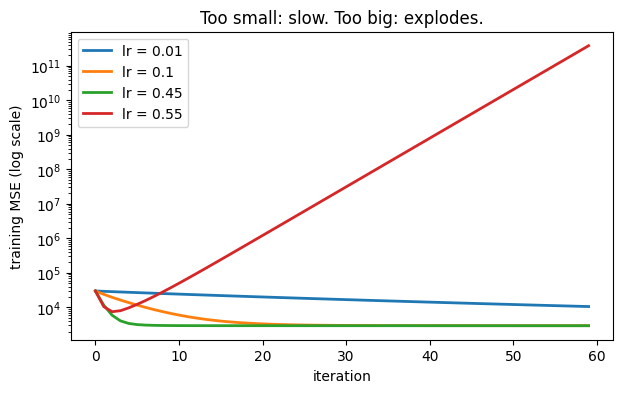

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.01, 0.1, 0.45, 0.55]:
    with np.errstate(all='ignore'):
        _, L = batch_gd(Xtr, y_train, lr=lr, max_iter=60)
    ax.plot(L, label=f'lr = {lr}', lw=2)
ax.set_yscale('log'); ax.set_xlabel('iteration'); ax.set_ylabel('training MSE (log scale)')
ax.set_title('Too small: slow. Too big: explodes.'); ax.legend(); plt.show()

## Level 5: mini-batch and stochastic GD (one function does all three)
Each **epoch**:
1. shuffle the row order: `perm = rng.permutation(m)`, then `X, y = X[perm], y[perm]`
2. walk through the data in slices of `bs` rows: `X[start:start+bs]`
3. do one gradient step **per slice** (same formula as Level 4, with m = the slice size)

- `bs = m` → **batch GD** (one step per epoch)
- `bs = 1` → **stochastic GD** (m steps per epoch)
- in between → **mini-batch**

Return `theta`.

<details><summary>Hint</summary>

`for start in range(0, m, bs):` gives 0, bs, 2bs, … The last slice may be smaller, and that's fine: use `Xb.shape[0]` as its m.
</details>

In [16]:
def minibatch_gd(X, y, lr=0.05, epochs=100, bs=32, seed=0):
    rng = np.random.default_rng(seed)
    theta = np.zeros(X.shape[1])
    m = X.shape[0]
    # start = 0
    # YOUR CODE HERE  (my solution: 7 lines)

    print(X.shape)
    print(y.shape)
    for e in range(epochs):
        perm = rng.permutation(m)
        X, y = X[perm], y[perm]
        # pred_epoch = X @ theta
        
        for start in range(0, m, bs):
            Xb = X[start:start + bs]
            yb = y[start:start + bs]

            # perm = rng.permutation(m)
            # X, y = X[perm], y[perm]

            pred = Xb @ theta
            yhat = pred - yb
            loss = mse(yhat, yb)

            gradient = (Xb.T @ yhat) / (Xb.shape[0])
            # print("X.shape: ", X.shape)

            start = start + bs
            theta = theta - (lr * gradient)

    #EPOCH FINISH
    return theta

checks.check_5(minibatch_gd)

(40, 4)
(40,)
(40, 4)
(40,)
(40, 4)
(40,)
✅ Level 5 cleared. bs = m is batch GD, bs = 1 is SGD, anything between is mini-batch. One function, three methods.
   [█████████░░░░░░░░░░░░] 9/21


True

## Level 6: penalty classes (the professor's design)
Each penalty is a small class that knows two things: its **value** (added to the loss) and its **derivation** (added to the gradient).

| class | `__call__(theta)` (value) | `derivation(theta)` (gradient) |
|---|---|---|
| `Ridge(l)` | l·Σθ² | 2·l·θ |
| `Lasso(l)` | l·Σ\|θ\| | l·sign(θ) |
| `Elastic(l, l_ratio)` | l_ratio·l·Σ\|θ\| + (1 − l_ratio)·l·Σθ² | l·l_ratio·sign(θ) + 2·l·(1 − l_ratio)·θ |

`__call__` is what lets you write `Ridge(0.5)(theta)`, calling an object like a function.

<details><summary>Hint</summary>

`np.sum(np.square(theta))`, `np.sum(np.abs(theta))`, `np.sign(theta)`. Store `l` in `__init__` as `self.l = l`.
</details>

In [46]:
class Ridge:
    def __init__(self, l):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def __call__(self, theta):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def derivation(self, theta):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError


class Lasso:
    def __init__(self, l):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def __call__(self, theta):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def derivation(self, theta):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError


class Elastic:
    def __init__(self, l, l_ratio=0.5):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def __call__(self, theta):
        # YOUR CODE HERE  (my solution: 3 lines)
        raise NotImplementedError

    def derivation(self, theta):
        # YOUR CODE HERE  (my solution: 3 lines)
        raise NotImplementedError

checks.check_6(Ridge, Lasso, Elastic)

❌ Level 6: not written yet (it still raises NotImplementedError).


False

## Level 7: your own `LinearRegression` class
This is the professor's class from `03 - Regularization.ipynb`, without the k-fold and early-stopping parts (you build k-fold separately in Level 8).

- `__init__(self, regularization=None, lr=0.01, method='batch', num_epochs=500, bs=50)`: store everything.
- `fit(self, X, y)`: set `self.theta = np.zeros(n)`; for each epoch, shuffle, then
  - `'batch'`: one `_train` call on all rows
  - `'mini'`: one `_train` call per slice of `bs` rows
  - `'sto'`: one `_train` call per single row (`X[i:i+1]`, `y[i:i+1]`)
- `_train(self, X, y)`: predict → gradient `(1/m)·Xᵀ(ŷ − y)` **+ `self.regularization.derivation(self.theta)` if there is one** → update → return the mse
- `predict(self, X)`: `X @ self.theta`

**Why the check compares Ridge with (XᵀX + 2mλI)⁻¹Xᵀy:** GD stops where the gradient is 0, so (1/m)Xᵀ(Xθ − y) + 2λθ = 0. Multiply by m: (XᵀX + 2mλI)θ = Xᵀy.
So **the professor's GD λ equals sklearn's α divided by 2m**. Same idea, different bookkeeping.

<details><summary>Hint</summary>

Use `rng = np.random.default_rng(0)` and `perm = rng.permutation(m)` for shuffling. For "if there is one": `if self.regularization is not None:`.
</details>

In [ ]:
class LinearRegression:
    def __init__(self, regularization=None, lr=0.01, method='batch', num_epochs=500, bs=50):
        # YOUR CODE HERE  (my solution: 5 lines)
        raise NotImplementedError

    def mse(self, ytrue, ypred):
        return ((ypred - ytrue) ** 2).sum() / ytrue.shape[0]

    def fit(self, X, y):
        rng = np.random.default_rng(0)
        m, n = X.shape
        self.theta = np.zeros(n)
        # YOUR CODE HERE  (my solution: 13 lines)
        raise NotImplementedError
        return self

    def _train(self, X, y):
        # YOUR CODE HERE  (my solution: 7 lines)
        raise NotImplementedError

    def predict(self, X):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

checks.check_7(LinearRegression, Ridge)

### 👀 Experiment (just run it): Lasso makes coefficients exactly 0, Ridge only shrinks them
This is the classic exam short answer: *"Lasso does feature selection."* Here is the picture, using sklearn for speed.

In [ ]:
from sklearn.linear_model import Lasso as SkLasso, Ridge as SkRidge
alphas = np.logspace(-2, 2, 30)
lasso_coefs = np.array([SkLasso(alpha=a, max_iter=20000).fit(X_train_s, y_train).coef_ for a in alphas])
ridge_coefs = np.array([SkRidge(alpha=a * 50).fit(X_train_s, y_train).coef_ for a in alphas])
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axs[0].plot(alphas, ridge_coefs); axs[0].set_title('Ridge: shrinks smoothly, never exactly 0')
axs[1].plot(alphas, lasso_coefs); axs[1].set_title('Lasso: coefficients hit exactly 0, one by one')
for a in axs: a.set_xscale('log'); a.set_xlabel('penalty strength'); a.axhline(0, color='k', lw=0.5)
axs[0].set_ylabel('coefficient'); plt.show()
print('Lasso coefficients that are exactly 0 at the strongest penalty:', int((lasso_coefs[-1] == 0).sum()), 'of 10')

---
# Block C

## Level 8: cross-validation from scratch
### 8a · `kfold_indices(m, k)`
Split row numbers 0 … m−1 into k **consecutive** chunks (no shuffling, like `KFold(n_splits=k)`).
For each chunk: `val_idx` = the chunk, `train_idx` = everything else. Return a list of `(train_idx, val_idx)` pairs.

**Detail sklearn uses:** if m isn't divisible by k, the **first** `m % k` folds get one extra row. For m = 23, k = 5 the fold sizes are 5, 5, 5, 4, 4.

<details><summary>Hint</summary>

`sizes = np.full(k, m // k); sizes[: m % k] += 1`, then walk a `start` pointer. `np.setdiff1d(np.arange(m), val_idx)` gives the rest.
</details>

In [ ]:
def kfold_indices(m, k):
    # YOUR CODE HERE  (my solution: 9 lines)
    raise NotImplementedError

checks.check_8a(kfold_indices)

### 8b · Let the data choose λ
`cv_mse_ridge(X, y, lam, k)`: for each fold, fit `ridge_closed_form` on the training part, compute `mse` on the validation part, and return the **mean** over folds.
Then try every λ in `lams` and set `best_lam` to the one with the lowest CV MSE.

This answers the question you asked earlier: *"doesn't it depend on the data?"* Yes, and this loop is how the data decides.

In [ ]:
def cv_mse_ridge(X, y, lam, k=5):
    # YOUR CODE HERE  (my solution: 5 lines)
    raise NotImplementedError

lams = [0, 1, 10, 30, 100, 300, 1000]
best_lam = None
# YOUR CODE HERE  (my solution: 4 lines)

checks.check_8b(cv_mse_ridge, best_lam, Xtr, y_train, lams)

## Level 9: the sklearn versions (prove they're the same math)
### 9a · `sklearn.linear_model.LinearRegression`
Fit it on `X_train_s` (**without** the 1s column: sklearn adds its own intercept), and compute `theta_cf = closed_form(Xtr, y_train)`.
The check proves `intercept_ = θ₀` and `coef_ = θ₁…θₙ`.

(We import it as `SkLinearRegression` so it doesn't overwrite *your* class.)

In [ ]:
from sklearn.linear_model import LinearRegression as SkLinearRegression
sk_lr, theta_cf = None, None
# YOUR CODE HERE  (my solution: 2 lines)
checks.check_9a(sk_lr, theta_cf)

### 9b · `sklearn.linear_model.Ridge`
Fit `Ridge(alpha=10, fit_intercept=False)` on `Xtr` (which already has the 1s column), and compute `theta_ridge = ridge_closed_form(Xtr, y_train, 10)`.

In [ ]:
from sklearn.linear_model import Ridge as SkRidge
sk_ridge, theta_ridge = None, None
# YOUR CODE HERE  (my solution: 2 lines)
checks.check_9b(sk_ridge, theta_ridge)

### 9c · `GridSearchCV` with a `Pipeline` (Part 2 asks for grid search)
Build `Pipeline([('scaler', StandardScaler()), ('model', Ridge())])` and search `{'model__alpha': [0.01, 0.1, 1, 10, 100]}`
with `cv=5, scoring='neg_mean_squared_error'`. Fit it on the **raw** `X_train_raw`.

**Why the scaler goes inside the pipeline:** then each CV fold is scaled using only its own training part, so there's no leakage between folds.

<details><summary>Hint</summary>

`from sklearn.model_selection import GridSearchCV` · `from sklearn.pipeline import Pipeline` · `gs = GridSearchCV(pipe, grid, cv=5, scoring=...).fit(X_train_raw, y_train)`. Note the double underscore in `model__alpha`: step name, two underscores, parameter.
</details>

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
gs = None
# YOUR CODE HERE  (my solution: 5 lines)
checks.check_9c(gs, X_train_raw, y_train)

---
# Block D: logistic regression

## Level 10: the three pieces
- `sigmoid(z)` = 1 / (1 + e^(−z))
- `bce(y, h)` = −Σ[y·ln h + (1 − y)·ln(1 − h)]   (**summed**, like the professor's `ce`)
- `logistic_grad(X, y, theta)` = Xᵀ(h − y), where h = sigmoid(Xθ)   ← **the same shape as linear regression's Xᵀ(ŷ − y)**

The check uses your Drill Lab screenshot: x = [1, 2], θ = [0, 0.5], y = 1 → loss 0.3133, gradient [−0.269, −0.538].

In [ ]:
def sigmoid(z):
    # YOUR CODE HERE  (my solution: 1 line)
    raise NotImplementedError

def bce(y, h):
    # YOUR CODE HERE  (my solution: 1 line)
    raise NotImplementedError

def logistic_grad(X, y, theta):
    # YOUR CODE HERE  (my solution: 2 lines)
    raise NotImplementedError

checks.check_10(sigmoid, bce, logistic_grad)

## Level 11: train it, then measure it
### Data (given): the professor's `make_classification` setup

In [ ]:
from sklearn.datasets import make_classification
Xc, yc = make_classification(n_samples=500, n_features=10, n_redundant=2, n_informative=4,
                             n_clusters_per_class=2, random_state=14)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3, random_state=42, stratify=yc)
sc = StandardScaler().fit(Xc_train)
Ctr = np.insert(sc.transform(Xc_train), 0, 1, axis=1)
Cte = np.insert(sc.transform(Xc_test), 0, 1, axis=1)
print(Ctr.shape, Cte.shape, '· class balance in train:', np.bincount(yc_train))

### 11a · `fit_logistic(X, y, lr, max_iter)`: batch GD
Same three steps as Level 4: h = sigmoid(Xθ) → gradient **(1/m)·Xᵀ(h − y)** → update. Store the **mean** cross-entropy (`bce(y, h) / m`) in `losses` each iteration.
Return `(theta, losses)`.

In [ ]:
def fit_logistic(X, y, lr=0.5, max_iter=1000):
    theta = np.zeros(X.shape[1])
    losses = []
    # YOUR CODE HERE  (my solution: 6 lines)
    raise NotImplementedError
    return theta, losses

checks.check_11a(fit_logistic, Ctr, yc_train)

### 👀 Experiment (just run it): see the decision boundary
A separate 2-feature dataset, so we can draw it. The shading is h, the predicted probability. The black line is where θᵀx = 0, i.e. h = 0.5: points on the red side are predicted class 1.

In [ ]:
X2d, y2d = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2,
                               n_clusters_per_class=1, class_sep=1.3, random_state=3)
X2 = np.insert(StandardScaler().fit_transform(X2d), 0, 1, axis=1)     # intercept + 2 features
th2, L2 = fit_logistic(X2, y2d, lr=0.5, max_iter=500)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(L2, lw=2); axs[0].set_title('mean cross-entropy while training'); axs[0].set_xlabel('iteration')
g1, g2 = np.meshgrid(np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 200),
                     np.linspace(X2[:, 2].min() - 0.5, X2[:, 2].max() + 0.5, 200))
H = sigmoid(th2[0] + th2[1] * g1 + th2[2] * g2)
cs = axs[1].contourf(g1, g2, H, levels=10, cmap='coolwarm', alpha=0.35)
axs[1].contour(g1, g2, H, levels=[0.5], colors='k', linewidths=2)
axs[1].scatter(X2[:, 1], X2[:, 2], c=y2d, cmap='coolwarm', s=18, edgecolor='k', lw=0.3)
fig.colorbar(cs, ax=axs[1], label='h = P(y = 1)')
axs[1].set_title('black line: θ₀ + θ₁x₁ + θ₂x₂ = 0, i.e. h = 0.5')
plt.show()

### 11b · Confusion matrix and metrics from scratch (Part 2 asks for this)
`confusion(y_true, y_pred)` returns a 2×2 array in **sklearn's layout**: rows = true class, columns = predicted class.

|  | predicted 0 | predicted 1 |
|---|---|---|
| **true 0** | TN | FP |
| **true 1** | FN | TP |

Then `precision` = TP / (TP + FP), `recall` = TP / (TP + FN), `f1` = 2PR / (P + R).

<details><summary>Hint</summary>

`TP = np.sum((y_true == 1) & (y_pred == 1))`. Build the array with `np.array([[TN, FP], [FN, TP]])`. Inside `precision`, you can reuse `confusion` and unpack it: `(tn, fp), (fn, tp) = confusion(y_true, y_pred)`.
</details>

In [ ]:
def confusion(y_true, y_pred):
    # YOUR CODE HERE  (my solution: 5 lines)
    raise NotImplementedError

def precision(y_true, y_pred):
    # YOUR CODE HERE  (my solution: 2 lines)
    raise NotImplementedError

def recall(y_true, y_pred):
    # YOUR CODE HERE  (my solution: 2 lines)
    raise NotImplementedError

def f1(y_true, y_pred):
    # YOUR CODE HERE  (my solution: 2 lines)
    raise NotImplementedError

checks.check_11b(confusion, precision, recall, f1)

In [ ]:
# Use them on your Level 11a model (just run it)
theta_c, _ = fit_logistic(Ctr, yc_train, lr=0.5, max_iter=1000)
yc_pred = (sigmoid(Cte @ theta_c) >= 0.5).astype(int)
print('confusion:\n', confusion(yc_test, yc_pred))
print(f'accuracy {np.mean(yc_pred == yc_test):.3f} · precision {precision(yc_test, yc_pred):.3f} · '
      f'recall {recall(yc_test, yc_pred):.3f} · F1 {f1(yc_test, yc_pred):.3f}')

## Level 12: 🐉 BOSS: your `LogisticRegression` class on real data
The breast cancer dataset (569 patients, 30 features, malignant vs benign). The data cell is given.

Write a class with:
- `__init__(self, lr=0.1, max_iter=2000, method='batch', bs=32, l2=0.0)`
- `fit(self, X, y)`: GD with gradient (1/m)·Xᵀ(h − y) **+ 2·l2·θ**; `'batch'` or `'mini'`, like your Level 7 class
- `predict_proba(self, X)` → h, one probability per row
- `predict(self, X, threshold=0.5)` → 0/1 labels as ints

**To clear it:** your test accuracy must be within 0.03 of sklearn's `LogisticRegression`.
**Exam-speed challenge:** once cleared, delete the class and rewrite it from a blank cell in **under 15 minutes** without looking.

In [ ]:
from sklearn.datasets import load_breast_cancer
Xb, yb = load_breast_cancer(return_X_y=True)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.3, random_state=42, stratify=yb)
sb = StandardScaler().fit(Xb_train)
Btr = np.insert(sb.transform(Xb_train), 0, 1, axis=1)
Bte = np.insert(sb.transform(Xb_test), 0, 1, axis=1)
print(Btr.shape, Bte.shape)

In [ ]:
class LogisticRegression:
    def __init__(self, lr=0.1, max_iter=2000, method='batch', bs=32, l2=0.0):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def _step(self, X, y):
        """One gradient step on these rows: (1/m)·Xᵀ(h − y) + 2·l2·θ."""
        # YOUR CODE HERE  (my solution: 4 lines)
        raise NotImplementedError

    def fit(self, X, y):
        rng = np.random.default_rng(0)
        m, n = X.shape
        self.theta = np.zeros(n)
        # YOUR CODE HERE  (my solution: 8 lines)
        raise NotImplementedError
        return self

    def predict_proba(self, X):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        # YOUR CODE HERE  (my solution: 1 line)
        raise NotImplementedError

my_model = None
# YOUR CODE HERE  (my solution: 1 line)
checks.check_12(my_model, Btr, yb_train, Bte, yb_test)

In [ ]:
# Compare the reports side by side (just run it)
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
sk_log = SkLogisticRegression(max_iter=5000).fit(Btr[:, 1:], yb_train)
if my_model is not None:
    print('YOURS\n', classification_report(yb_test, my_model.predict(Bte), digits=3))
print('SKLEARN\n', classification_report(yb_test, sk_log.predict(Bte[:, 1:]), digits=3))

## Level 13 (bonus): softmax regression, 3 classes
Logistic regression for k classes. θ becomes a matrix **Θ of shape (n, k)**, one column per class.
- Scores Z = XΘ, shape (m, k)
- `softmax(Z)`: e^Z divided by its row sum, so each row becomes probabilities summing to 1. **Subtract each row's max first** so e^1000 doesn't overflow (the check tests this).
- `one_hot(y, k)`: label 2 → [0, 0, 1]
- Gradient: **(1/m)·Xᵀ(H − Y)**, where H = softmax(XΘ) and Y = one_hot(y). Once again the same shape.
- Predict: `argmax` along each row.

<details><summary>Hint</summary>

`np.exp(Z - Z.max(axis=1, keepdims=True))`, then divide by `.sum(axis=1, keepdims=True)`. `np.eye(k)[y]` is a one-line one-hot.
</details>

In [ ]:
def softmax(Z):
    # YOUR CODE HERE  (my solution: 2 lines)
    raise NotImplementedError

def one_hot(y, k):
    # YOUR CODE HERE  (my solution: 1 line)
    raise NotImplementedError

checks.check_13a(softmax, one_hot)

In [ ]:
from sklearn.datasets import load_iris
Xi, yi = load_iris(return_X_y=True)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)
si = StandardScaler().fit(Xi_train)
Itr = np.insert(si.transform(Xi_train), 0, 1, axis=1)
Ite = np.insert(si.transform(Xi_test), 0, 1, axis=1)

yi_pred = None
# YOUR CODE HERE  (my solution: 7 lines)
checks.check_13b(yi_pred, yi_test)

---
## Scoreboard

In [ ]:
checks.scoreboard()

### When everything is ✅: exam-speed runs
Open a blank notebook and, **without looking**, time yourself:
1. `batch_gd` + `minibatch_gd` (Levels 4–5): target 10 minutes
2. The `LinearRegression` class with Ridge (Levels 6–7): target 15 minutes
3. The `LogisticRegression` class + confusion matrix (Levels 11–12): target 15 minutes

If you can do all three, Part 2's "from scratch" parts are covered up to logistic regression.